# Soft Actor-Critic Agent Testing Guide on Pendulum-v1

This notebook tests the SAC implementation on a continuous-control environment. The default configuration is a compact smoke test; increase `MAX_STEPS` for a longer experiment.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path
import sys

import gymnasium as gym

DEEP_RL_DIR = Path('/home/dangineer/Learnspaces/coursera/reinforcement-learning-specialization/rl-lab/deep-rl')
if str(DEEP_RL_DIR) not in sys.path:
    sys.path.insert(0, str(DEEP_RL_DIR))

POLICY_GRADIENT_DIR = Path.cwd()
if POLICY_GRADIENT_DIR.name != 'policy-gradient':
    POLICY_GRADIENT_DIR = Path('/home/dangineer/Learnspaces/coursera/reinforcement-learning-specialization/rl-lab/deep-rl/policy-gradient')
if str(POLICY_GRADIENT_DIR) not in sys.path:
    sys.path.insert(0, str(POLICY_GRADIENT_DIR))

from sac import SACAgent

## 1. Configure the Experiment

`Pendulum-v1` has a three-dimensional observation and one continuous action, matching this SAC implementation.

In [3]:
ENV_ID = 'Pendulum-v1'
SEED = 2026
MAX_STEPS = 10_000
HIDDEN_DIMS = (64, 64)
ACTOR_LR = 3e-4
CRITIC_LR = 3e-4
ALPHA_LR = 3e-4
GAMMA = 0.99
TAU = 0.005
INITIAL_ALPHA = 0.2
AUTO_ENTROPY_TUNING = True
BATCH_SIZE = 64
BUFFER_SIZE = 10_000
START_STEPS = 100
MAX_GRAD_NORM = 1.0

print(f'Environment: {ENV_ID}')
print(f'Seed: {SEED}')
print(f'Total steps: {MAX_STEPS}')
print(f'Warmup steps: {START_STEPS}')

Environment: Pendulum-v1
Seed: 2026
Total steps: 10000
Warmup steps: 100


## 2. Create the Environment and Train SAC

SAC samples actions from its stochastic policy during training and uses the policy mean during evaluation.

In [4]:
env = gym.make(ENV_ID)
env.reset(seed=SEED)
env.action_space.seed(SEED)

state_dim = env.observation_space.shape[0]
action_dim = env.action_space.shape[0]
max_action = float(env.action_space.high[0])

agent = SACAgent(
    state_dim=state_dim,
    action_dim=action_dim,
    max_action=max_action,
    actor_hidden_dims=HIDDEN_DIMS,
    critic_hidden_dims=HIDDEN_DIMS,
    actor_lr=ACTOR_LR,
    critic_lr=CRITIC_LR,
    alpha_lr=ALPHA_LR,
    gamma=GAMMA,
    tau=TAU,
    alpha=INITIAL_ALPHA,
    auto_entropy_tuning=AUTO_ENTROPY_TUNING,
    buffer_size=BUFFER_SIZE,
    batch_size=BATCH_SIZE,
    start_steps=START_STEPS,
    max_grad_norm=MAX_GRAD_NORM,
    seed=SEED,
)

print(f'State dim: {state_dim}, Action dim: {action_dim}')
print(f'Action range: [{env.action_space.low[0]}, {env.action_space.high[0]}]')
metrics = agent.learn(env, max_steps=MAX_STEPS)

print('Training metrics:')
for name, value in metrics.items():
    print(f'  {name}: {value}')

State dim: 3, Action dim: 1
Action range: [-2.0, 2.0]
Training metrics:
  actor_loss: 100.75262664165922
  critic_loss: 4.7255257438010805
  critic2_loss: 4.155126004023524
  alpha: 0.38664220173411173
  q_value: -101.25672068704733
  q2_value: -101.28744678328346
  episode_return: -829.0217315587475
  episode_length: 200.0
  total_steps: 10000


## 3. Inspect the Training Metrics

Automatic entropy tuning updates `log_alpha` and reconstructs the positive entropy coefficient `alpha`.

In [5]:
metric_descriptions = {
    'actor_loss': 'Entropy-regularized policy objective.',
    'critic_loss': 'First Q-function prediction error.',
    'critic2_loss': 'Second Q-function prediction error.',
    'alpha': 'Current positive entropy coefficient.',
    'q_value': 'Mean estimate from the first Q-function.',
    'q2_value': 'Mean estimate from the second Q-function.',
}

assert metrics['total_steps'] == MAX_STEPS
assert metrics['alpha'] > 0.0
for name, description in metric_descriptions.items():
    print(f'{name}: {metrics[name]}')
    print(f'  {description}')

actor_loss: 100.75262664165922
  Entropy-regularized policy objective.
critic_loss: 4.7255257438010805
  First Q-function prediction error.
critic2_loss: 4.155126004023524
  Second Q-function prediction error.
alpha: 0.38664220173411173
  Current positive entropy coefficient.
q_value: -101.25672068704733
  Mean estimate from the first Q-function.
q2_value: -101.28744678328346
  Mean estimate from the second Q-function.


## 4. Evaluate the Deterministic Policy

Evaluation uses the mean action instead of sampling from the policy distribution.

In [6]:
evaluation_env = gym.make(ENV_ID)
evaluation_env.reset(seed=SEED + 1)
evaluation_env.action_space.seed(SEED + 1)
evaluation_return = agent.evaluate(evaluation_env, num_episodes=2)
evaluation_env.close()
env.close()

print(f'Mean evaluation return over 2 episodes: {evaluation_return:.3f}')
assert isinstance(evaluation_return, float)

Mean evaluation return over 2 episodes: -120.538


## 5. Hyperparameter Tuning

For longer experiments, increase `MAX_STEPS` and `buffer_size`. The main settings to tune are:

- **`auto_entropy_tuning` and `target_entropy`**: keep `auto_entropy_tuning=True` so the entropy coefficient `alpha` is learned instead of hand-tuned. The default `target_entropy` is `-action_dim`. Raise it for more exploration, lower it for a more deterministic policy.
- **`actor_lr`, `critic_lr` and `alpha_lr`**: typically `3e-4` for all three. If training is unstable, lower them first. If the Q-loss is slow to converge, try a higher `critic_lr` such as `1e-3`.
- **`gamma`**: the discount factor (`0.99`). Lower values favor short-term reward.
- **`tau`**: the soft update rate for target networks (`0.005`). Smaller values give more stable targets but slower learning.
- **`batch_size`**: `256`. Larger batches reduce gradient noise at a higher compute cost.
- **`start_steps`**: the number of initial random-action steps (e.g. `1_000`) that seed the replay buffer before the policy takes over.
- **`actor_hidden_dims` and `critic_hidden_dims`**: `(256, 256)` is sufficient for most standard continuous-control benchmarks. Increase for harder tasks.

## 6. Visualize Trained Agent Performance

Run the trained policy on a newly seeded `Pendulum-v1` instance, record RGB frames, and render the resulting episode as an animated GIF.

Visual evaluation episode completed with total return: -122.84


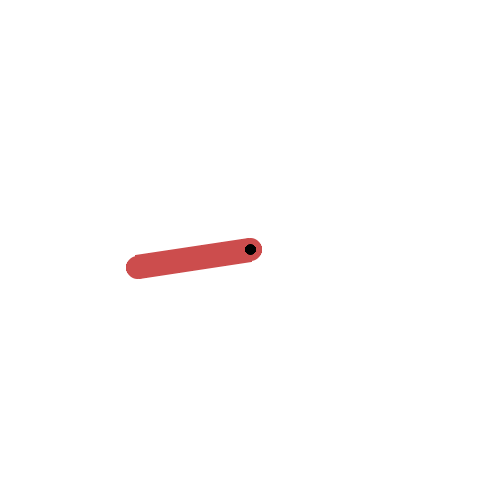

In [ ]:
import imageio
from IPython.display import Image, display

def visualize_agent(agent, env_id=ENV_ID, seed=SEED + 42, gif_path='assets/pendulum_sac.gif', fps=30):
    vis_env = gym.make(env_id, render_mode="rgb_array")
    state, _ = vis_env.reset(seed=seed)
    vis_env.action_space.seed(seed)

    frames = [vis_env.render()]
    episode_reward = 0.0
    done = False

    while not done:
        action = agent.select_action(state, evaluate=True)
        state, reward, terminated, truncated, _ = vis_env.step(action)
        episode_reward += reward
        frames.append(vis_env.render())
        done = terminated or truncated

    vis_env.close()
    imageio.mimsave(gif_path, frames, fps=fps, loop=0)
    print(f"Visual evaluation episode completed with total return: {episode_reward:.2f}")
    return Image(filename=gif_path)

display(visualize_agent(agent))
